# Pragya — Resolution-Time Prediction (Regression)

This notebook builds a CPU-friendly, production-oriented regression pipeline for predicting help-desk ticket resolution duration.

**Prediction contract:** a point estimate of elapsed resolution duration in **hours**, made at ticket creation time. The model uses only creation-time ticket attributes and calendar features. It does not use final status, resolution timestamps, workflow totals, comments accumulated after creation, future assignment changes, ticket IDs, or other post-resolution fields.

The notebook is intentionally data-driven: it discovers the local `Help Desk Tickets` directory, audits the actual files and documentation, verifies timestamp semantics, and stops rather than fabricating a target if a defensible resolution timestamp is unavailable.

## Acceptance criteria and operating assumptions

- Use the one-row-per-ticket `issues.csv` table for the ticket-level target. `issues_snapshot.csv` is an assignee-turn table and is audited but not joined into the ticket-level training set.
- Define elapsed resolution duration as `issue_resolution_date - issue_created` only when both timestamps parse and the duration is non-negative.
- Treat tickets without a resolution timestamp as unresolved/censored observations; do not turn them into zero-hour targets.
- Split chronologically into approximately 70% train, 15% validation, and 15% test. The test set is untouched until final evaluation.
- Use a small, time-aware randomized search with at most two parallel jobs.
- Save the fitted pipeline, metrics, parameters, feature definitions, metadata, plots, subgroup errors, and a generated report under `ml/artifacts/resolution/`.

The source dataset is the Mendeley Data release referenced by the repository README. Local documentation and local files are the source of truth for the execution below.

In [1]:
# Reproducibility, bounded CPU use, and automatic path discovery.
import os
import sys
import json
import math
import random
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

SEED = 42
N_JOBS = min(2, os.cpu_count() or 1)
for env_name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[env_name] = str(N_JOBS)
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display

def discover_data_dir() -> Path:
    candidates = []
    for base in (Path.cwd(), *Path.cwd().parents):
        candidates.extend([base / "Help Desk Tickets", base / "data" / "Help Desk Tickets"])
    for candidate in candidates:
        if (candidate / "issues.csv").exists():
            return candidate.resolve()
    for issue_file in Path.cwd().rglob("issues.csv"):
        if issue_file.parent.name.lower() == "help desk tickets":
            return issue_file.parent.resolve()
    raise FileNotFoundError("Could not find a Help Desk Tickets folder containing issues.csv")

DATA_DIR = discover_data_dir()
REPO_ROOT = DATA_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
ARTIFACT_DIR = REPO_ROOT / "ml" / "artifacts" / "resolution"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

from ml.resolution_predictor import (
    CATEGORICAL_FEATURES,
    ENGINEERED_FEATURE_COLUMNS,
    NUMERIC_FEATURES,
    build_resolution_features,
    predict_resolution_time,
)

SOURCE_URL = "https://data.mendeley.com/datasets/btm76zndnt/3"
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "figure.dpi": 110})

package_versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "joblib": joblib.__version__,
}
print("Repository:", REPO_ROOT)
print("Dataset directory:", DATA_DIR)
print("Artifacts directory:", ARTIFACT_DIR)
print("Seed:", SEED, "| bounded jobs:", N_JOBS)
display(pd.Series(package_versions, name="version"))

Repository: C:\Users\Acer\Desktop\Projects\OpsPilot-AI
Dataset directory: C:\Users\Acer\Desktop\Projects\OpsPilot-AI\Help Desk Tickets
Artifacts directory: C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\artifacts\resolution
Seed: 42 | bounded jobs: 2


python          3.11.9
pandas           3.1.0
numpy            2.4.6
scikit_learn     1.9.1
matplotlib      3.11.2
joblib           1.6.0
Name: version, dtype: str

## 1. Dataset audit — files, documentation, schemas, missingness, and timestamps

In [2]:
def parse_timestamp(values: pd.Series) -> pd.Series:
    # The source mixes timestamp precisions/formats; format='mixed' avoids false NaT values.
    try:
        return pd.to_datetime(values, errors="coerce", utc=True, format="mixed")
    except TypeError:  # pandas < 2.0 compatibility
        return pd.to_datetime(values, errors="coerce", utc=True)

csv_files = sorted(DATA_DIR.glob("*.csv"))
file_inventory = pd.DataFrame(
    [
        {
            "file": path.name,
            "suffix": path.suffix,
            "size_mb": round(path.stat().st_size / (1024**2), 3),
        }
        for path in sorted(DATA_DIR.iterdir())
        if path.is_file()
    ]
)
display(file_inventory)

documentation = {}
for doc_name in ("FEATURES.md", "EXAMPLE.md", "README.md"):
    doc_path = DATA_DIR / doc_name
    if doc_path.exists():
        documentation[doc_name] = doc_path.read_text(encoding="utf-8", errors="replace")
print("Documentation found:", sorted(documentation))
if "FEATURES.md" in documentation:
    display(Markdown("**FEATURES.md excerpt**\n\n" + documentation["FEATURES.md"][:4500]))
if "EXAMPLE.md" in documentation:
    display(Markdown("**EXAMPLE.md excerpt**\n\n" + documentation["EXAMPLE.md"][:2500]))

def read_csv_if_present(name: str) -> pd.DataFrame | None:
    path = DATA_DIR / name
    return pd.read_csv(path, low_memory=False) if path.exists() else None

issues_df = read_csv_if_present("issues.csv")
snapshots_df = read_csv_if_present("issues_snapshot.csv")
history_df = read_csv_if_present("issues_change_history.csv")
utterances_df = read_csv_if_present("sample_utterances.csv")
holidays_df = read_csv_if_present("holidays_by_country.csv")
if issues_df is None:
    raise FileNotFoundError("issues.csv is required for the resolution-time target")

xlsx_path = DATA_DIR / "issues_snapshot_sample.xlsx"
xlsx_preview = pd.read_excel(xlsx_path, nrows=5) if xlsx_path.exists() else None

loaded_frames = {
    "issues.csv": issues_df,
    "issues_snapshot.csv": snapshots_df,
    "issues_change_history.csv": history_df,
    "sample_utterances.csv": utterances_df,
    "holidays_by_country.csv": holidays_df,
}
loaded_frames = {name: frame for name, frame in loaded_frames.items() if frame is not None}

schema_rows = []
for name, frame in loaded_frames.items():
    for column in frame.columns:
        schema_rows.append(
            {
                "file": name,
                "rows": len(frame),
                "column": column,
                "dtype": str(frame[column].dtype),
                "missing": int(frame[column].isna().sum()),
                "nunique": int(frame[column].nunique(dropna=True)),
            }
        )
schema_summary = pd.DataFrame(schema_rows)
print("Loaded shapes:")
display(pd.DataFrame({name: [frame.shape[0], frame.shape[1]] for name, frame in loaded_frames.items()}, index=["rows", "columns"]).T)
display(schema_summary)
if xlsx_preview is not None:
    print("issues_snapshot_sample.xlsx preview shape:", xlsx_preview.shape)
    display(xlsx_preview.head())

timestamp_rows = []
for name, frame in loaded_frames.items():
    for column in frame.columns:
        if any(token in column.lower() for token in ("created", "date", "started", "ended", "change")):
            parsed = parse_timestamp(frame[column])
            timestamp_rows.append(
                {
                    "file": name,
                    "column": column,
                    "parse_rate": round(float(parsed.notna().mean()), 6),
                    "missing_after_parse": int(parsed.isna().sum()),
                    "min_utc": parsed.min(),
                    "max_utc": parsed.max(),
                }
            )
timestamp_candidates = pd.DataFrame(timestamp_rows)
display(timestamp_candidates)
print("Duplicate full rows by file:", {name: int(frame.duplicated().sum()) for name, frame in loaded_frames.items()})

,file,suffix,size_mb
0,db.png,.png,0.454
1,EXAMPLE.md,.md,0.026
2,FEATURES.md,.md,0.014
3,holidays_by_country.csv,.csv,0.064
4,issues.csv,.csv,19.633
5,issues_change_history.csv,.csv,18.036
6,issues_snapshot.csv,.csv,27.169
7,issues_snapshot_sample.xlsx,.xlsx,0.101
8,process-flow.png,.png,0.046
9,sample_utterances.csv,.csv,3.224


Documentation found: ['EXAMPLE.md', 'FEATURES.md']


**FEATURES.md excerpt**

# Help Desk Tickets Datasets

## Data Masking

Some features in the datasets were masked to hide details that are related to the dataset provider to maintain
privacy, while maintaining the consistency and relations between the datasets. The features prefixed with # were
masked.

The issue_proj feature in issues.csv and issues_snapshot.csv defines an issue related project. It is defined by the
helpdesk team for internal and external projects. For the external projects, it is more than six characters that
follows a pattern of having two characters as the country code, a product key, and a 3+ characters client code.
For example, ZZ99ABC is key for product 99 for client ABC in country ZZ. 
It was found there were 18 unique countries codes for the external projects, and those codes were mapped while masking
the feature with C00 to C17, so in the previous example, if ZZ was mapped to C03, then the project code will be
C0378XPS, assuming that 99ABC was masked to 78XPS. 

## DataSets

### issues.csv

This dataset is a CSV file containing issues reported through the helpdesk system from January 2016 until
March 2023. Once an issue is reported by the customer, it walks through a workflow until it is resolved, noting that
some steps could be passed multiple times. Image [process-flow](./process-flow.png) describes the flow.

The below are the features:

| **Feature**           | **Type**    | **Description**                                                       |
|-----------------------|-------------|-----------------------------------------------------------------------|
| id                    | numeric     | The unique ID of the issue.                                           |
| issue_num             | numeric     | The unique sequence of the issue within the project.                  |
| # issue_proj          | text        | The issue's project code.                                             |
| # issue_reporter      | text        | The user ID who reported the issue.                                   |
| # issue_assignee      | text        | The last user ID assigned to work on  the issue.                      |
| issue_contr_count     | numeric     | The total number of users worked on this issue.                       |
| issue_priority        | categorical | The priority of the issue.                                            |
| issue_type            | categorical | The nature of the issue, like incident or service request.            |
| issue_created         | timestamp   | The creation time of the issue.                                       |
| issue_resolution_date | timestamp   | The resolution time of the issue.                                     |
| issue_resolution      | text        | One of the values: Done, Won't Do, Cannot Reproduce, or Duplicate.    |
| issue_status          | text        | The issue last status value: Done, In Progress, etc...                |
| issue_comments_count  | numeric     | The number of the issue comments.                                     |
| last_change_date      | timestamp   | The last time the issue was updated.                                  |
| wf_total_time         | numeric     | The total processing time for the issue (in seconds).                 |
| processing_steps      | numeric     | The number of steps the issue took until it reached its final status. |
|                       |             | **Repeated features for each step "S"**                               |
| wf_{S}                | numeric     | The time spent while the issue was in the "S" state.                  |
| wfe_{S}               | numeric     | The number of times the issue passed state "S".                       |

The wf_ and wfe_ features are the result of aggregations and calculations collected from the issues_change_history.csv.
The workflow steps that were found in the database are below, sorted by the mostly passed steps to the least:

- Open
- In progress
- Resolved
- Waiting
- Validation
- Resolved under monitoring
- Pending deployment
- Closed
- Reopened
- Cancelled
- In review
- To do
- Under review
- Rejected
- Done
- Approved

### issues_snapshot.csv

An issue could be handled by multiple support engineers, which requires to track each member activity separately.
This feature captures each assignee activity, which is gathered and calculated from the issues_change_history.csv
dataset. This dataset contains the same features as in issues.csv with the additional below featu

**EXAMPLE.md excerpt**

# Example Records

This document shows an example for all records related to an issue with ID 1004364 that was reported by user z8yz-3ygp.

The record in issues.csv shows that it took 81646 seconds (around 22 hours and 40 minutes) to resolve the issue by two
members, according to issue\_contr\_count feature.
It passed through steps: open, "in progress", and resolved in 64, 81049, and 533 seconds respectively according
to the features wf\_open, wf\_in\_progress, and wf\_resolved. Those times were calculated according to the history
in issues_change_history.csv dataset.
This record also shows there was a total of six comments on this ticket by the reporter, the assignee, and other members
as listed in the sample_utterances.csv.

In the issues\_snapshots.csv, there are two records for this issue, as it was processed by two members 4hghq and 4sii.
User 4hghq worked on this issue for 257 seconds (around 4 minutes and 20 seconds) and 4sii for 81389 seconds
(around 22 hours and 35 minutes). Each record in the snapshots dataset shows the number of comments and workflow
processing
time for each assignment.

The helpdesk manager evaluated the performance for both users on this ticket in the issues_snapshot_sample.xlsx as
below:

| Assignee | Q1 | Q2 | Q3 | Notes                                                                      |
|----------|----|----|----|----------------------------------------------------------------------------|
| 4hghq    | 5  | 5  | 5  | Service Desk user did his work perfectly same for other service desk users |
| 4sii     | 2  | 2  | 3  | This is not an issue they used helpdesk to share files                     |

## Data in issues.csv

| id        | started                   | ended                     | issue\_num | issue\_proj | issue\_reporter | issue\_assignee | issue\_contr\_count | issue\_type | issue\_priority | issue\_created            | issue\_resolution\_date   | issue\_resolution | issue\_status | issue\_comments\_count | last\_change\_date        | wf\_in\_review | wfe\_in\_review | wf\_deployment | wfe\_deployment | wf\_resolved | wfe\_resolved | wf\_open | wfe\_open | wf\_monitoring | wfe\_monitoring | wf\_done | wfe\_done | wf\_pending\_customer\_approval | wfe\_pending\_customer\_approval | wf\_rejected | wfe\_rejected | wf\_testing\_monitoring | wfe\_testing\_monitoring | wf\_in\_progress | wfe\_in\_progress | wf\_reopened | wfe\_reopened | wf\_to\_do | wfe\_to\_do | wf\_validation | wfe\_validation | wf\_resolved\_unde

Loaded shapes:


...

,file,rows,column,dtype,missing,nunique
0,issues.csv,66691,id,float64,0,66691
1,issues.csv,66691,started,str,0,66281
2,issues.csv,66691,ended,str,0,65786
3,issues.csv,66691,issue_num,float64,0,3542
4,issues.csv,66691,issue_proj,str,0,358
...,...,...,...,...,...,...
130,sample_utterances.csv,30104,is_private,float64,0,2
131,sample_utterances.csv,30104,actionbody,str,23,8365
132,sample_utterances.csv,30104,author_role,str,0,3
133,holidays_by_country.csv,4479,country,str,0,18


issues_snapshot_sample.xlsx preview shape: (5, 19)


,id,no,project,reporter,type,priority,contributors,turn_no,assignee,started,ended,spent hours,steps,comments count,valid,Q1,Q2,Q3,Notes
0,1004298.0,346.0,C11gg0w13,.wy0w13yhr,Ticket,High,1.0,1,4ops,2022-01-02 11:12:51+00:00,2022-05-24 05:40:13+00:00,3402.456,2,49,True,5,5,5,This is an HD-Service
1,1004357.0,155.0,C01gg1_3_,z8y1_3_ygi,Ticket,Medium,1.0,1,4lip,2022-01-05 05:27:14+00:00,2022-01-12 07:47:47+00:00,170.342,3,4,True,3,4,4,This is an HD-Service and looks like communica...
2,1004361.0,14.0,C02hk0x93,0ny0x93yik,Ticket,Medium,3.0,1,4hghs,2022-01-05 06:50:56+00:00,2022-01-05 06:55:23+00:00,0.074,2,3,True,5,5,5,Service Desk user did his work perfectly same ...
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,4kgr,2022-01-05 06:55:23+00:00,2022-05-31 12:11:20+00:00,3509.266,2,21,True,1,1,1,No Follow up or update to client
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,4lhl,2022-05-31 12:11:20+00:00,2023-01-02 06:27:09+00:00,5178.264,3,19,True,1,1,1,No Follow up or update to client


,file,column,parse_rate,missing_after_parse,min_utc,max_utc
0,issues.csv,started,1.000000,0,2007-04-15 08:12:11.000000000+00:00,2023-03-14 14:00:32.000000000+00:00
1,issues.csv,ended,1.000000,0,2013-01-07 09:45:42.000000000+00:00,2023-03-14 14:19:32.000000000+00:00
2,issues.csv,issue_created,1.000000,0,2007-04-15 08:12:11.000000000+00:00,2023-03-14 14:00:32.000000000+00:00
3,issues.csv,issue_resolution_date,0.987210,853,2013-01-07 09:45:42.000000000+00:00,2023-03-14 14:19:28.000000000+00:00
4,issues.csv,last_change_date,0.999985,1,2016-04-02 11:59:22.000000000+00:00,2023-03-14 14:19:32.000000000+00:00
5,issues_snapshot.csv,started,1.000000,0,2007-04-15 08:12:11.000000000+00:00,2023-03-14 14:00:32.000000000+00:00
6,issues_snapshot.csv,ended,1.000000,0,2013-01-07 09:45:42.000000000+00:00,2023-03-14 14:19:32.000000000+00:00
7,issues_snapshot.csv,issue_created,1.000000,0,2007-04-15 08:12:11.000000000+00:00,2023-03-14 14:00:32.000000000+00:00
8,issues_snapshot.csv,issue_resolution_date,0.984114,1445,2013-01-07 09:45:42.000000000+00:00,2023-03-14 14:19:28.000000000+00:00
9,issues_snapshot.csv,last_change_date,0.999989,1,2016-04-02 11:59:22.000000000+00:00,2023-03-14 14:19:32.000000000+00:00


Duplicate full rows by file: {'issues.csv': 0, 'issues_snapshot.csv': 0, 'issues_change_history.csv': 0, 'sample_utterances.csv': 0, 'holidays_by_country.csv': 0}


## 2. Row granularity and file relationships

In [3]:
def first_existing(frame: pd.DataFrame, candidates: list[str], label: str) -> str:
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    raise KeyError(f"Could not identify {label}; checked {candidates}")

ticket_id_col = first_existing(issues_df, ["id", "issue_id", "ticket_id"], "ticket ID")
issue_num_col = first_existing(issues_df, ["issue_num", "issue_number"], "issue number") if any(c in issues_df.columns for c in ["issue_num", "issue_number"]) else None
snapshot_id_col = first_existing(snapshots_df, ["id", "issue_id", "ticket_id"], "snapshot ticket ID") if snapshots_df is not None else None
history_issue_col = first_existing(history_df, ["issueid", "issue_id", "id"], "history issue ID") if history_df is not None else None
utterance_issue_col = first_existing(utterances_df, ["issueid", "issue_id", "id"], "utterance issue ID") if utterances_df is not None else None

relationship_rows = [
    {"relationship": "issues rows", "value": len(issues_df)},
    {"relationship": "unique ticket IDs in issues", "value": issues_df[ticket_id_col].nunique(dropna=True)},
    {"relationship": "duplicate ticket IDs in issues", "value": int(issues_df[ticket_id_col].duplicated().sum())},
]
if snapshots_df is not None:
    relationship_rows.extend(
        [
            {"relationship": "snapshot rows", "value": len(snapshots_df)},
            {"relationship": "unique ticket IDs in snapshots", "value": snapshots_df[snapshot_id_col].nunique(dropna=True)},
            {"relationship": "mean snapshots per ticket", "value": round(float(snapshots_df.groupby(snapshot_id_col).size().mean()), 4)},
            {"relationship": "max snapshots per ticket", "value": int(snapshots_df.groupby(snapshot_id_col).size().max())},
            {"relationship": "issues IDs present in snapshots", "value": round(float(issues_df[ticket_id_col].isin(snapshots_df[snapshot_id_col]).mean()), 6)},
        ]
    )
if history_df is not None:
    relationship_rows.extend(
        [
            {"relationship": "history rows", "value": len(history_df)},
            {"relationship": "unique issues in history", "value": history_df[history_issue_col].nunique(dropna=True)},
            {"relationship": "history fields", "value": history_df["field"].value_counts(dropna=False).to_dict() if "field" in history_df.columns else {}},
        ]
    )
if utterances_df is not None:
    relationship_rows.extend(
        [
            {"relationship": "sample utterance rows", "value": len(utterances_df)},
            {"relationship": "unique issues in sample utterances", "value": utterances_df[utterance_issue_col].nunique(dropna=True)},
        ]
    )
display(pd.DataFrame(relationship_rows))
if snapshots_df is not None:
    print("Snapshot row granularity: one row per assignee turn, not one row per ticket.")
if issue_num_col is not None:
    print("issue_num unique values:", issues_df[issue_num_col].nunique(dropna=True), "of", len(issues_df), "rows; it is not a global ticket key.")
assert issues_df[ticket_id_col].notna().all(), "Ticket IDs must be present for split integrity checks"
assert issues_df[ticket_id_col].is_unique, "The ticket-level issues table has duplicate ticket IDs; stop and resolve granularity before training"

,relationship,value
0,issues rows,66691
1,unique ticket IDs in issues,66691
2,duplicate ticket IDs in issues,0
3,snapshot rows,90963
4,unique ticket IDs in snapshots,66691
5,mean snapshots per ticket,1.3639
6,max snapshots per ticket,15
7,issues IDs present in snapshots,1.0
8,history rows,257508
9,unique issues in history,66650


Snapshot row granularity: one row per assignee turn, not one row per ticket.
issue_num unique values: 3542 of 66691 rows; it is not a global ticket key.


## 3. Target definition and exclusions

The local `FEATURES.md` documentation describes `issue_created` as the issue creation time and `issue_resolution_date` as the resolution time. `EXAMPLE.md` shows the same fields for a completed ticket and distinguishes them from workflow processing-time aggregates. The target below therefore uses the elapsed wall-clock difference between those two timestamp fields, measured in hours.

This is a historical resolved-ticket regression target, not a survival model. Tickets without a resolution timestamp are unresolved/censored observations and are excluded from supervised regression rather than assigned a duration of zero. The final `issue_resolution` categories (`Done`, `Won't Do`, `Duplicate`, and `Cannot Reproduce`) are retained because they represent observed resolution outcomes; the final label itself is not used as a predictor.

In [4]:
created_col = first_existing(issues_df, ["issue_created", "created", "created_at"], "creation timestamp")
resolution_col = first_existing(issues_df, ["issue_resolution_date", "resolution_date", "resolved_at"], "resolution timestamp")
status_col = first_existing(issues_df, ["issue_status", "status", "final_status"], "status") if any(c in issues_df.columns for c in ["issue_status", "status", "final_status"]) else None
resolution_label_col = first_existing(issues_df, ["issue_resolution", "resolution", "resolution_label"], "resolution outcome") if any(c in issues_df.columns for c in ["issue_resolution", "resolution", "resolution_label"]) else None

created_ts = parse_timestamp(issues_df[created_col])
resolution_ts = parse_timestamp(issues_df[resolution_col])
duration_hours = (resolution_ts - created_ts).dt.total_seconds() / 3600.0
negative_duration = duration_hours.notna() & (duration_hours < 0)
target_reason = np.select(
    [created_ts.isna(), resolution_ts.isna(), negative_duration, duration_hours.isna()],
    [
        "missing_or_invalid_creation_timestamp",
        "unresolved_missing_resolution_timestamp",
        "negative_duration",
        "invalid_duration",
    ],
    default="included",
)
valid_target_mask = target_reason == "included"
valid_tickets = issues_df.loc[valid_target_mask].copy()
valid_tickets["_created_ts"] = created_ts.loc[valid_target_mask]
valid_tickets["_resolution_ts"] = resolution_ts.loc[valid_target_mask]
valid_tickets["resolution_duration_hours"] = duration_hours.loc[valid_target_mask].astype("float64")

target_audit = pd.Series(target_reason).value_counts().rename_axis("target_decision").reset_index(name="rows")
display(target_audit)
target_summary = valid_tickets["resolution_duration_hours"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame("hours")
display(target_summary)
if status_col is not None:
    print("Observed statuses among included targets:")
    display(valid_tickets[status_col].value_counts(dropna=False).rename("rows").to_frame())
if resolution_label_col is not None:
    print("Observed resolution outcomes among included targets:")
    display(valid_tickets[resolution_label_col].value_counts(dropna=False).rename("rows").to_frame())

reopened_count = 0
if "wfe_reopened" in valid_tickets.columns:
    reopened_count = int(pd.to_numeric(valid_tickets["wfe_reopened"], errors="coerce").fillna(0).gt(0).sum())
print(f"Included resolved tickets: {len(valid_tickets):,}")
print(f"Unresolved/censored tickets excluded: {int((target_reason == 'unresolved_missing_resolution_timestamp').sum()):,}")
print(f"Negative durations excluded: {int(negative_duration.sum()):,}")
print(f"Included tickets with a recorded reopen count > 0: {reopened_count:,}; final elapsed duration remains the target.")
if len(valid_tickets) == 0:
    raise ValueError("The dataset does not support a defensible resolution-time target")

,target_decision,rows
0,included,65838
1,unresolved_missing_resolution_timestamp,853


,hours
count,65838.000000
mean,18482.548659
std,27805.944918
min,0.000833
1%,0.032222
5%,1.043889
25%,124.322778
50%,837.807849
75%,36508.149060
90%,67592.330903


Observed statuses among included targets:


,rows
issue_status,
closed,56152
done,9686


Observed resolution outcomes among included targets:


,rows
issue_resolution,
Done,62034
Won't Do,2991
Duplicate,661
Cannot Reproduce,152


Included resolved tickets: 65,838
Unresolved/censored tickets excluded: 853
Negative durations excluded: 0
Included tickets with a recorded reopen count > 0: 2,099; final elapsed duration remains the target.


## 4. Leakage prevention and approved prediction-time features

The prediction time is the ticket creation event. The model therefore uses only fields documented as ticket attributes at creation plus deterministic calendar features from the creation timestamp:

- `issue_priority`, `issue_type`, and `issue_proj` when present in the verified ticket table.
- `created_year`, `created_month`, `created_dayofweek`, `created_hour`, `created_dayofmonth`, and `created_is_weekend`.

Excluded fields include ticket IDs and sequence numbers; final resolution/status fields; final timestamps; final assignee/contributor totals; comment totals that accumulate after creation; workflow durations and pass counts; processing-step totals; history-derived future assignee/status changes; and the partial sample utterance table. `issue_reporter` is intentionally not used: it is a high-cardinality user identifier and is not necessary for a defensible creation-time baseline.

The three static categorical fields are treated as available at creation because they are stored as issue attributes in the source documentation. Production integration should confirm that the event payload exposes them before the prediction request is made.

In [5]:
approved_raw_columns = [column for column in [created_col, "issue_priority", "issue_type", "issue_proj"] if column in valid_tickets.columns]
required_static_columns = ["issue_priority", "issue_type", "issue_proj"]
missing_static_columns = [column for column in required_static_columns if column not in valid_tickets.columns]
if missing_static_columns:
    raise ValueError(f"Required creation-time fields are missing: {missing_static_columns}")

exclusion_rows = []
for column in issues_df.columns:
    lower = column.lower()
    if column in {ticket_id_col, issue_num_col}:
        reason = "identifier or within-project sequence; not a predictor"
    elif column in {resolution_col, resolution_label_col, status_col, "last_change_date", "started", "ended"}:
        reason = "final/post-resolution timestamp or state"
    elif lower.startswith("wf_") or lower.startswith("wfe_") or column in {"wf_total_time", "processing_steps"}:
        reason = "workflow aggregate derived from the full ticket history"
    elif column in {"issue_assignee", "issue_contr_count", "issue_comments_count", "issue_reporter"}:
        reason = "final/high-cardinality/post-creation field excluded from the creation-time baseline"
    elif column in required_static_columns:
        reason = "approved creation-time predictor"
    else:
        reason = "not selected; requires a separate availability review"
    exclusion_rows.append({"column": column, "decision": "used" if reason == "approved creation-time predictor" else "excluded", "reason": reason})
leakage_audit = pd.DataFrame(exclusion_rows)
display(leakage_audit)

feature_definitions = pd.DataFrame(
    [
        {"feature": "issue_priority", "source": "issues.csv", "availability": "ticket creation", "type": "categorical", "leakage_decision": "approved"},
        {"feature": "issue_type", "source": "issues.csv", "availability": "ticket creation", "type": "categorical", "leakage_decision": "approved"},
        {"feature": "issue_proj", "source": "issues.csv", "availability": "ticket creation", "type": "categorical", "leakage_decision": "approved"},
        {"feature": "created_year", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
        {"feature": "created_month", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
        {"feature": "created_dayofweek", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
        {"feature": "created_hour", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
        {"feature": "created_dayofmonth", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
        {"feature": "created_is_weekend", "source": created_col, "availability": "ticket creation", "type": "numeric calendar", "leakage_decision": "approved"},
    ]
)
display(feature_definitions)

,column,decision,reason
0,id,excluded,identifier or within-project sequence; not a p...
1,started,excluded,final/post-resolution timestamp or state
2,ended,excluded,final/post-resolution timestamp or state
3,issue_num,excluded,identifier or within-project sequence; not a p...
4,issue_proj,used,approved creation-time predictor
5,issue_reporter,excluded,final/high-cardinality/post-creation field exc...
6,issue_assignee,excluded,final/high-cardinality/post-creation field exc...
7,issue_contr_count,excluded,final/high-cardinality/post-creation field exc...
8,issue_type,used,approved creation-time predictor
9,issue_priority,used,approved creation-time predictor


,feature,source,availability,type,leakage_decision
0,issue_priority,issues.csv,ticket creation,categorical,approved
1,issue_type,issues.csv,ticket creation,categorical,approved
2,issue_proj,issues.csv,ticket creation,categorical,approved
3,created_year,issue_created,ticket creation,numeric calendar,approved
4,created_month,issue_created,ticket creation,numeric calendar,approved
5,created_dayofweek,issue_created,ticket creation,numeric calendar,approved
6,created_hour,issue_created,ticket creation,numeric calendar,approved
7,created_dayofmonth,issue_created,ticket creation,numeric calendar,approved
8,created_is_weekend,issue_created,ticket creation,numeric calendar,approved


## 5. Exploratory data analysis

Target quantiles in hours:


,hours
0.01,0.032222
0.05,1.043889
0.25,124.322778
0.50,837.807849
0.75,36508.149060
0.90,67592.330903
0.95,76751.133903
0.99,90928.992125


,missing_rate
issue_priority,0.0
issue_type,0.0
issue_proj,0.0


Priority breakdown:


,rows,median_hours,mean_hours
issue_priority,,,
unknown,33965,34149.399270,34598.410002
Medium,24249,238.495250,1515.500544
High,4381,120.465278,591.166669
Highest,2018,91.914722,485.932557
Blocker,641,90.560833,1148.224775
Low,501,216.564444,1107.473304
Lowest,83,230.029722,1304.830034


Issue-type breakdown:


,rows,median_hours,mean_hours
issue_type,,,
Ticket,44693,1001.421641,20960.727052
Service,5177,326.749853,1031.027750
Subtask,4746,57605.713302,51586.881956
Story,4538,281.124722,2210.192540
HD Service,1673,285.494600,744.153261
Task,1538,334.654286,1640.878007
Vacation,856,100.778611,492.115421
Project,741,1144.731242,3426.322198
Sub-task,544,277.432230,9774.899509


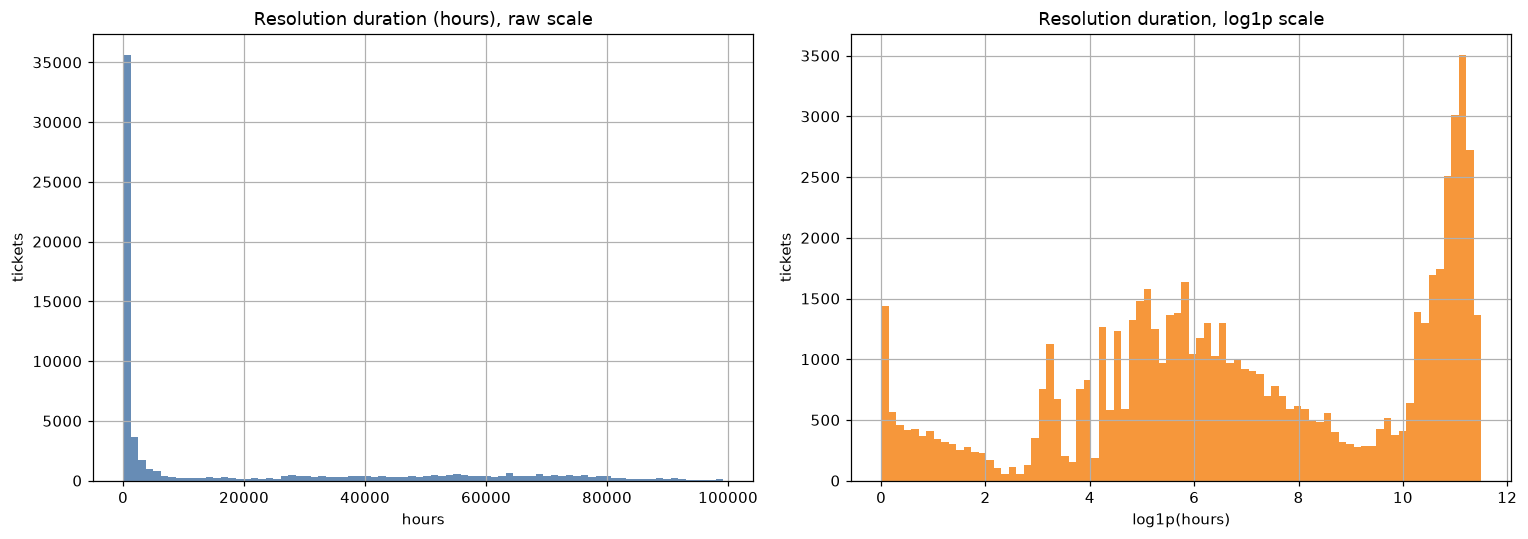

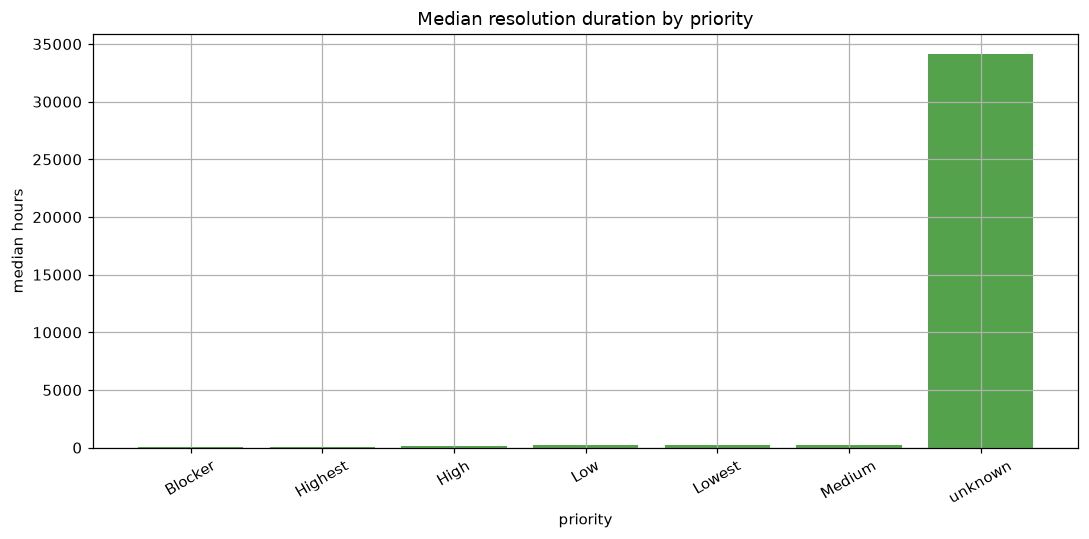

In [6]:
duration_series = valid_tickets["resolution_duration_hours"]
print("Target quantiles in hours:")
display(duration_series.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).rename("hours").to_frame())

missingness = valid_tickets[required_static_columns].isna().mean().sort_values(ascending=False).rename("missing_rate").to_frame()
display(missingness)

priority_breakdown = (
    valid_tickets.groupby("issue_priority", dropna=False)["resolution_duration_hours"]
    .agg(rows="size", median_hours="median", mean_hours="mean")
    .sort_values("rows", ascending=False)
)
type_breakdown = (
    valid_tickets.groupby("issue_type", dropna=False)["resolution_duration_hours"]
    .agg(rows="size", median_hours="median", mean_hours="mean")
    .sort_values("rows", ascending=False)
)
print("Priority breakdown:")
display(priority_breakdown)
print("Issue-type breakdown:")
display(type_breakdown)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(duration_series, bins=80, color="#4c78a8", alpha=0.85)
axes[0].set_title("Resolution duration (hours), raw scale")
axes[0].set_xlabel("hours")
axes[0].set_ylabel("tickets")
axes[1].hist(np.log1p(duration_series), bins=80, color="#f58518", alpha=0.85)
axes[1].set_title("Resolution duration, log1p scale")
axes[1].set_xlabel("log1p(hours)")
axes[1].set_ylabel("tickets")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "target_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

priority_plot = priority_breakdown.sort_values("median_hours")
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(priority_plot.index.astype(str), priority_plot["median_hours"], color="#54a24b")
ax.set_title("Median resolution duration by priority")
ax.set_xlabel("priority")
ax.set_ylabel("median hours")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "target_by_priority.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Chronological train/validation/test split

In [7]:
model_df = valid_tickets.copy()
model_df = model_df.sort_values("_created_ts").reset_index(drop=True)
n_rows = len(model_df)
n_train = int(n_rows * 0.70)
n_validation = int(n_rows * 0.15)
train_df = model_df.iloc[:n_train].copy()
validation_df = model_df.iloc[n_train : n_train + n_validation].copy()
test_df = model_df.iloc[n_train + n_validation :].copy()

def split_info(name: str, frame: pd.DataFrame) -> dict:
    return {
        "split": name,
        "rows": len(frame),
        "first_created": frame["_created_ts"].min(),
        "last_created": frame["_created_ts"].max(),
        "unique_tickets": frame[ticket_id_col].nunique(),
    }

split_table = pd.DataFrame([split_info("train", train_df), split_info("validation", validation_df), split_info("test", test_df)])
display(split_table)
train_ids, validation_ids, test_ids = (set(frame[ticket_id_col]) for frame in (train_df, validation_df, test_df))
assert not train_ids.intersection(validation_ids)
assert not train_ids.intersection(test_ids)
assert not validation_ids.intersection(test_ids)
assert len(train_df) + len(validation_df) + len(test_df) == n_rows

def make_features(frame: pd.DataFrame) -> pd.DataFrame:
    engineered = build_resolution_features(frame, created_column=created_col)
    # Keep an explicit, stable column order for the saved preprocessing pipeline.
    return engineered.loc[:, list(ENGINEERED_FEATURE_COLUMNS)]

X_train = make_features(train_df)
X_validation = make_features(validation_df)
X_test = make_features(test_df)
y_train = train_df["resolution_duration_hours"].to_numpy(dtype="float64")
y_validation = validation_df["resolution_duration_hours"].to_numpy(dtype="float64")
y_test = test_df["resolution_duration_hours"].to_numpy(dtype="float64")
print("Engineered feature columns:", list(X_train.columns))

,split,rows,first_created,last_created,unique_tickets
0,train,46086,2007-04-15 08:12:11.000+00:00,2019-10-13 08:06:49.871+00:00,46086
1,validation,9875,2019-10-13 08:07:39.501+00:00,2021-08-08 14:02:40.000+00:00,9875
2,test,9877,2021-08-08 14:07:06.000+00:00,2023-03-14 11:43:55.000+00:00,9877


Engineered feature columns: ['issue_priority', 'issue_type', 'issue_proj', 'created_year', 'created_month', 'created_dayofweek', 'created_hour', 'created_dayofmonth', 'created_is_weekend']


## 7. Preprocessing, baselines, and candidate regression models

In [8]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_one_hot_encoder() -> OneHotEncoder:
    kwargs = {"handle_unknown": "ignore", "min_frequency": 10, "dtype": np.float32}
    try:
        return OneHotEncoder(sparse_output=False, **kwargs)
    except TypeError:  # scikit-learn < 1.2 compatibility
        return OneHotEncoder(sparse=False, **kwargs)

def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot", make_one_hot_encoder()),
        ]
    )
    return ColumnTransformer(
        [
            ("numeric", numeric_pipeline, list(NUMERIC_FEATURES)),
            ("categorical", categorical_pipeline, list(CATEGORICAL_FEATURES)),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def make_pipeline(estimator, *, scale_numeric: bool = False) -> Pipeline:
    return Pipeline(
        [
            ("preprocessor", make_preprocessor(scale_numeric)),
            ("model", estimator),
        ]
    )

def model_factories() -> dict[str, callable]:
    return {
        "MedianBaseline": lambda: make_pipeline(DummyRegressor(strategy="median")),
        "Ridge": lambda: make_pipeline(Ridge(alpha=10.0), scale_numeric=True),
        "RandomForestRegressor": lambda: make_pipeline(
            RandomForestRegressor(
                n_estimators=150,
                max_depth=16,
                min_samples_leaf=5,
                max_features="sqrt",
                random_state=SEED,
                n_jobs=N_JOBS,
            )
        ),
        "HistGradientBoostingRegressor": lambda: make_pipeline(
            HistGradientBoostingRegressor(
                max_iter=150,
                learning_rate=0.05,
                max_leaf_nodes=31,
                min_samples_leaf=30,
                l2_regularization=1.0,
                random_state=SEED,
            )
        ),
    }

def regression_metrics(y_true: np.ndarray, prediction: np.ndarray) -> dict[str, float]:
    prediction = np.asarray(prediction, dtype="float64")
    return {
        "mae_hours": float(mean_absolute_error(y_true, prediction)),
        "rmse_hours": float(np.sqrt(mean_squared_error(y_true, prediction))),
        "r2": float(r2_score(y_true, prediction)) if len(np.unique(y_true)) > 1 else float("nan"),
    }

factories = model_factories()

In [9]:
candidate_models = {}
validation_predictions = {}
comparison_rows = []
for model_name, factory in factories.items():
    model = factory()
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    prediction = model.predict(X_validation)
    metrics = regression_metrics(y_validation, prediction)
    candidate_models[model_name] = model
    validation_predictions[model_name] = prediction
    comparison_rows.append(
        {
            "model": model_name,
            "validation_mae_hours": metrics["mae_hours"],
            "validation_rmse_hours": metrics["rmse_hours"],
            "validation_r2": metrics["r2"],
            "fit_seconds": fit_seconds,
            "tuned": False,
        }
    )

candidate_comparison = pd.DataFrame(comparison_rows).sort_values("validation_mae_hours").reset_index(drop=True)
display(candidate_comparison)
print("The test set is still untouched; validation MAE determines the next tuning decision.")

,model,validation_mae_hours,validation_rmse_hours,validation_r2,fit_seconds,tuned
0,HistGradientBoostingRegressor,1174.821720,2513.735569,-0.201210,13.865247,False
1,RandomForestRegressor,3521.351370,4201.784117,-2.356194,10.168404,False
2,MedianBaseline,4866.244459,5024.808799,-3.799751,0.565228,False
3,Ridge,17948.960381,19895.051118,-74.243625,0.726709,False


The test set is still untouched; validation MAE determines the next tuning decision.


## 8. Bounded hyperparameter optimisation

The stronger untuned tree model on the validation set is selected for a small randomized search. Search folds are chronological `TimeSeriesSplit` folds within the training period only; the validation and test periods are not used for parameter fitting. The budget is eight configurations, at most two parallel jobs, conservative tree sizes, and no large parameter grid.

In [10]:
from joblib import parallel_backend
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

tree_model_names = ["RandomForestRegressor", "HistGradientBoostingRegressor"]
untuned_tree_comparison = candidate_comparison[candidate_comparison["model"].isin(tree_model_names)]
selected_tree_name = untuned_tree_comparison.sort_values("validation_mae_hours").iloc[0]["model"]
if selected_tree_name == "RandomForestRegressor":
    search_space = {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_leaf": [2, 5, 10, 20],
        "model__max_features": ["sqrt", 0.7, 1.0],
    }
else:
    search_space = {
        "model__max_iter": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.10],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [10, 20, 40, 80],
        "model__l2_regularization": [0.0, 1.0, 10.0],
    }

cv_strategy = TimeSeriesSplit(n_splits=3)
search = RandomizedSearchCV(
    estimator=factories[selected_tree_name](),
    param_distributions=search_space,
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=cv_strategy,
    random_state=SEED,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    refit=True,
    return_train_score=False,
    verbose=0,
)
tuning_start = time.perf_counter()
with parallel_backend("threading", n_jobs=N_JOBS):
    search.fit(X_train, y_train)
tuning_seconds = time.perf_counter() - tuning_start
tuned_model = search.best_estimator_
tuned_validation_prediction = tuned_model.predict(X_validation)
tuned_validation_metrics = regression_metrics(y_validation, tuned_validation_prediction)
tuned_model_name = f"Tuned {selected_tree_name}"
validation_predictions[tuned_model_name] = tuned_validation_prediction
comparison_rows.append(
    {
        "model": tuned_model_name,
        "validation_mae_hours": tuned_validation_metrics["mae_hours"],
        "validation_rmse_hours": tuned_validation_metrics["rmse_hours"],
        "validation_r2": tuned_validation_metrics["r2"],
        "fit_seconds": tuning_seconds,
        "tuned": True,
    }
)
model_comparison = pd.DataFrame(comparison_rows).sort_values("validation_mae_hours").reset_index(drop=True)
display(model_comparison)
print("Selected tree for tuning:", selected_tree_name)
print("Best parameters:", search.best_params_)
print("Time-aware search seconds:", round(tuning_seconds, 3))

,model,validation_mae_hours,validation_rmse_hours,validation_r2,fit_seconds,tuned
0,Tuned HistGradientBoostingRegressor,1089.978137,2371.292772,-0.068932,120.469091,True
1,HistGradientBoostingRegressor,1174.821720,2513.735569,-0.201210,13.865247,False
2,RandomForestRegressor,3521.351370,4201.784117,-2.356194,10.168404,False
3,MedianBaseline,4866.244459,5024.808799,-3.799751,0.565228,False
4,Ridge,17948.960381,19895.051118,-74.243625,0.726709,False


Selected tree for tuning: HistGradientBoostingRegressor
Best parameters: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 31, 'model__max_iter': 150, 'model__learning_rate': 0.1, 'model__l2_regularization': 1.0}
Time-aware search seconds: 120.469


## 9. Model selection using validation MAE only

In [11]:
selected_model_name = model_comparison.sort_values("validation_mae_hours").iloc[0]["model"]
if selected_model_name == tuned_model_name:
    selected_estimator = tuned_model
else:
    selected_estimator = candidate_models[selected_model_name]

untuned_tree_mae = float(candidate_comparison.loc[candidate_comparison["model"] == selected_tree_name, "validation_mae_hours"].iloc[0])
tuned_tree_mae = float(model_comparison.loc[model_comparison["model"] == tuned_model_name, "validation_mae_hours"].iloc[0])
tuning_improvement_hours = untuned_tree_mae - tuned_tree_mae
print("Selected model:", selected_model_name)
print("Tuning validation MAE change (positive means improvement):", round(tuning_improvement_hours, 4), "hours")
if tuning_improvement_hours > 0:
    print("Measured result: tuning improved validation MAE for the selected tree model.")
elif tuning_improvement_hours < 0:
    print("Measured result: tuning worsened validation MAE; the untuned tree remains preferable if it wins overall.")
else:
    print("Measured result: tuning did not change validation MAE at the displayed precision.")
display(model_comparison)

Selected model: Tuned HistGradientBoostingRegressor
Tuning validation MAE change (positive means improvement): 84.8436 hours
Measured result: tuning improved validation MAE for the selected tree model.


,model,validation_mae_hours,validation_rmse_hours,validation_r2,fit_seconds,tuned
0,Tuned HistGradientBoostingRegressor,1089.978137,2371.292772,-0.068932,120.469091,True
1,HistGradientBoostingRegressor,1174.821720,2513.735569,-0.201210,13.865247,False
2,RandomForestRegressor,3521.351370,4201.784117,-2.356194,10.168404,False
3,MedianBaseline,4866.244459,5024.808799,-3.799751,0.565228,False
4,Ridge,17948.960381,19895.051118,-74.243625,0.726709,False


## 10. Final evaluation on the untouched test set

The selected model is cloned and refit once on train plus validation data. Only then is it evaluated on the chronological test period. Metrics are reported in hours. Because the target is extremely right-skewed, plots include a log1p visualization for readability; the reported MAE, RMSE, and R² remain on the original hour scale.

Selected model: Tuned HistGradientBoostingRegressor
Final test metrics: {'mae_hours': 692.2122519700815, 'rmse_hours': 1215.477947110974, 'r2': -0.0981746247308648, 'n_test': 9877, 'fit_seconds_train_validation': 13.638378400006332}
Train+validation median baseline metrics on test: {'mae_hours': 1371.163090968552, 'rmse_hours': 1547.9085451204483, 'r2': -0.781016046948799}
Final test MAE improvement over median baseline: 678.9508 hours


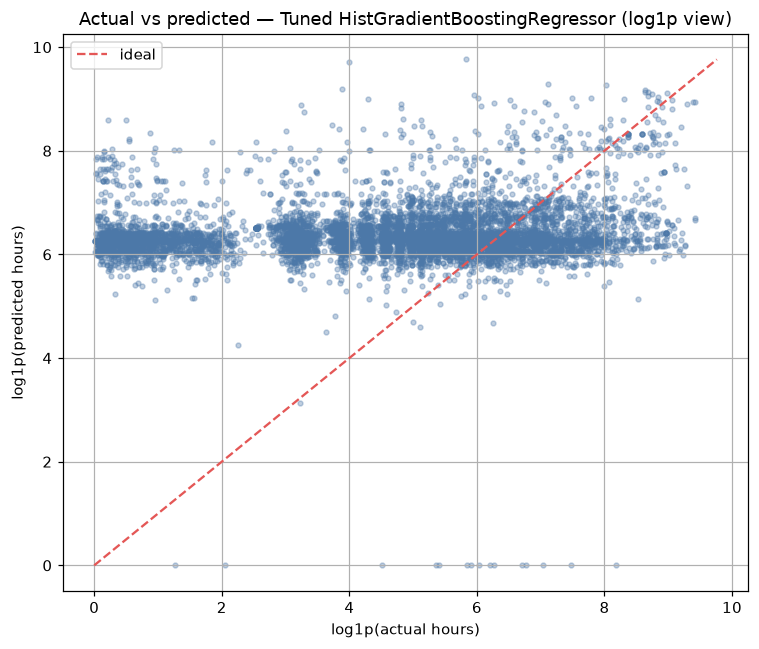

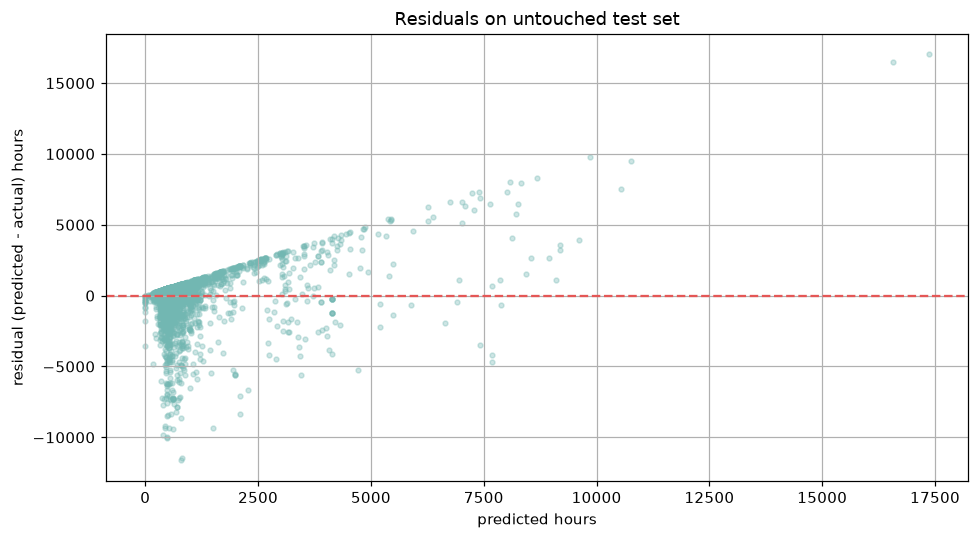

,feature,group,n,mae_hours,rmse_hours
0,issue_priority,Medium,4539,706.876305,1265.619298
1,issue_priority,High,3086,652.299264,1102.026168
2,issue_priority,Highest,1475,635.220067,1120.934906
3,issue_priority,Blocker,500,786.185933,1077.883477
4,issue_priority,Low,258,1060.376117,2088.259436
...,...,...,...,...,...
57,issue_type,Ticket,8589,602.746438,1049.984104
58,issue_type,Service,798,881.293075,1433.974747
59,issue_type,HD Service,199,1017.714950,1670.085020
60,issue_type,Deployment,198,2027.643225,2244.001723


In [12]:
train_validation_df = pd.concat([train_df, validation_df], ignore_index=True)
X_train_validation = make_features(train_validation_df)
y_train_validation = train_validation_df["resolution_duration_hours"].to_numpy(dtype="float64")
final_estimator = clone(selected_estimator)
final_fit_start = time.perf_counter()
final_estimator.fit(X_train_validation, y_train_validation)
final_fit_seconds = time.perf_counter() - final_fit_start
test_prediction = np.maximum(np.asarray(final_estimator.predict(X_test), dtype="float64"), 0.0)
final_test_metrics = regression_metrics(y_test, test_prediction)
final_test_metrics.update({"n_test": int(len(y_test)), "fit_seconds_train_validation": float(final_fit_seconds)})

train_validation_median = float(np.median(y_train_validation))
test_baseline_prediction = np.full_like(y_test, train_validation_median, dtype="float64")
test_baseline_metrics = regression_metrics(y_test, test_baseline_prediction)
test_baseline_improvement = test_baseline_metrics["mae_hours"] - final_test_metrics["mae_hours"]
print("Selected model:", selected_model_name)
print("Final test metrics:", final_test_metrics)
print("Train+validation median baseline metrics on test:", test_baseline_metrics)
print("Final test MAE improvement over median baseline:", round(test_baseline_improvement, 4), "hours")

rng = np.random.default_rng(SEED)
plot_size = min(8000, len(y_test))
plot_indices = rng.choice(len(y_test), size=plot_size, replace=False)
actual_plot = y_test[plot_indices]
predicted_plot = test_prediction[plot_indices]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(np.log1p(actual_plot), np.log1p(predicted_plot), s=10, alpha=0.35, color="#4c78a8")
limits = [0, max(float(np.log1p(actual_plot).max()), float(np.log1p(predicted_plot).max()))]
ax.plot(limits, limits, "--", color="#e45756", label="ideal")
ax.set_xlabel("log1p(actual hours)")
ax.set_ylabel("log1p(predicted hours)")
ax.set_title(f"Actual vs predicted — {selected_model_name} (log1p view)")
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "actual_vs_predicted.png", bbox_inches="tight")
plt.show()
plt.close(fig)

residuals = test_prediction - y_test
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(test_prediction[plot_indices], residuals[plot_indices], s=10, alpha=0.35, color="#72b7b2")
ax.axhline(0, color="#e45756", linestyle="--")
ax.set_xlabel("predicted hours")
ax.set_ylabel("residual (predicted - actual) hours")
ax.set_title("Residuals on untouched test set")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "residuals.png", bbox_inches="tight")
plt.show()
plt.close(fig)

def subgroup_error_table(frame: pd.DataFrame, actual: np.ndarray, predicted: np.ndarray, min_group_size: int = 50) -> pd.DataFrame:
    frame = frame.reset_index(drop=True)
    rows = []
    for column in ["issue_priority", "issue_type", "issue_proj"]:
        if column not in frame.columns:
            continue
        groups = frame[column].astype("string").fillna("<missing>")
        for group_value, positions in groups.groupby(groups).groups.items():
            positions = list(positions)
            if len(positions) >= min_group_size:
                rows.append(
                    {
                        "feature": column,
                        "group": str(group_value),
                        "n": len(positions),
                        "mae_hours": float(mean_absolute_error(actual[positions], predicted[positions])),
                        "rmse_hours": float(np.sqrt(mean_squared_error(actual[positions], predicted[positions]))),
                    }
                )
    return pd.DataFrame(rows).sort_values(["feature", "n"], ascending=[True, False]).reset_index(drop=True)

subgroup_errors = subgroup_error_table(test_df, y_test, test_prediction)
display(subgroup_errors)

## 11. Interpretability

Permutation importance is computed on the engineered input columns using the untouched test period. It measures how much shuffling a column changes predictive error for this fitted model; it is not a causal effect and should not be interpreted as a business intervention claim.

,feature,mean_increase_in_mae_hours,std_increase_in_mae_hours
0,issue_proj,55.737894,4.515069
1,issue_type,7.642010,1.328242
2,created_hour,0.582817,2.193924
3,issue_priority,-2.167662,0.828292
4,created_dayofweek,-4.365740,0.204541
5,created_is_weekend,-4.598748,0.000000
6,created_year,-4.598748,0.000000
7,created_dayofmonth,-4.911039,2.181444
8,created_month,-6.404945,3.115120


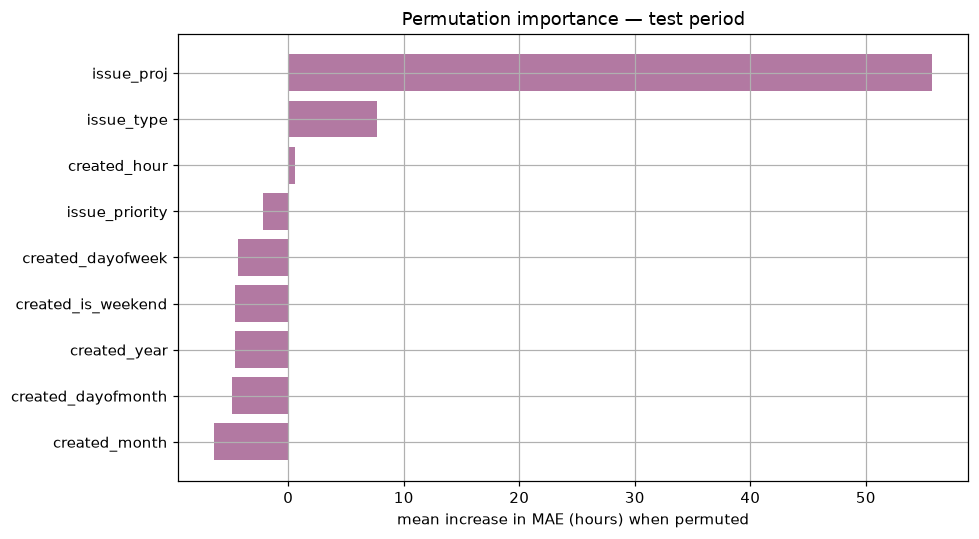

In [13]:
from sklearn.inspection import permutation_importance

try:
    permutation_result = permutation_importance(
        final_estimator,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=3,
        random_state=SEED,
        n_jobs=1,
        max_samples=min(5000, len(X_test)),
    )
except TypeError:  # older scikit-learn without max_samples
    permutation_result = permutation_importance(
        final_estimator,
        X_test,
        y_test,
        scoring="neg_mean_absolute_error",
        n_repeats=3,
        random_state=SEED,
        n_jobs=1,
    )
permutation_importance_df = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "mean_increase_in_mae_hours": permutation_result.importances_mean,
            "std_increase_in_mae_hours": permutation_result.importances_std,
        }
    )
    .sort_values("mean_increase_in_mae_hours", ascending=False)
    .reset_index(drop=True)
)
display(permutation_importance_df)
fig, ax = plt.subplots(figsize=(9, 5))
top_importance = permutation_importance_df.head(12).sort_values("mean_increase_in_mae_hours")
ax.barh(top_importance["feature"], top_importance["mean_increase_in_mae_hours"], color="#b279a2")
ax.set_xlabel("mean increase in MAE (hours) when permuted")
ax.set_title("Permutation importance — test period")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "permutation_importance.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 12. Artifact export, reusable prediction interface, and generated final report

In [14]:
def jsonable(value):
    if isinstance(value, dict):
        return {str(key): jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [jsonable(item) for item in value]
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value

transformed_feature_names = list(final_estimator.named_steps["preprocessor"].get_feature_names_out())
artifact_paths = {
    "model": ARTIFACT_DIR / "resolution_model.joblib",
    "metrics": ARTIFACT_DIR / "metrics.json",
    "best_parameters": ARTIFACT_DIR / "best_params.json",
    "model_comparison": ARTIFACT_DIR / "model_comparison.csv",
    "feature_definitions": ARTIFACT_DIR / "feature_definitions.csv",
    "metadata": ARTIFACT_DIR / "metadata.json",
    "subgroup_errors": ARTIFACT_DIR / "subgroup_errors.csv",
    "permutation_importance": ARTIFACT_DIR / "permutation_importance.csv",
    "tuning_cv_results": ARTIFACT_DIR / "tuning_cv_results.csv",
    "report": ARTIFACT_DIR / "final_report.md",
}
joblib.dump(final_estimator, artifact_paths["model"], compress=3)
model_comparison.to_csv(artifact_paths["model_comparison"], index=False)
feature_definitions.to_csv(artifact_paths["feature_definitions"], index=False)
subgroup_errors.to_csv(artifact_paths["subgroup_errors"], index=False)
permutation_importance_df.to_csv(artifact_paths["permutation_importance"], index=False)
pd.DataFrame(search.cv_results_).to_csv(artifact_paths["tuning_cv_results"], index=False)

validation_best_row = model_comparison.sort_values("validation_mae_hours").iloc[0].to_dict()
metrics_payload = {
    "target": {
        "definition": f"({resolution_col} - {created_col}) in elapsed hours",
        "unit": "hours",
        "prediction_type": "point_estimate",
        "included_rows": int(len(valid_tickets)),
        "excluded_rows_by_reason": target_audit.set_index("target_decision")["rows"].to_dict(),
        "duration_quantiles_hours": jsonable(duration_series.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).to_dict()),
    },
    "splits": split_table.to_dict(orient="records"),
    "validation_model_selection": {
        "selected_model": selected_model_name,
        "best_validation_row": jsonable(validation_best_row),
        "comparison": jsonable(model_comparison.to_dict(orient="records")),
    },
    "tuning": {
        "selected_tree_for_search": selected_tree_name,
        "n_iter": 8,
        "cv": "TimeSeriesSplit(n_splits=3)",
        "n_jobs": N_JOBS,
        "runtime_seconds": tuning_seconds,
        "untuned_tree_validation_mae_hours": untuned_tree_mae,
        "tuned_tree_validation_mae_hours": tuned_tree_mae,
        "tuning_improvement_hours": tuning_improvement_hours,
    },
    "final_test": jsonable(final_test_metrics),
    "test_median_baseline": jsonable(test_baseline_metrics),
    "test_baseline_improvement_hours": test_baseline_improvement,
    "feature_counts": {"raw_engineered": len(ENGINEERED_FEATURE_COLUMNS), "after_preprocessing": len(transformed_feature_names)},
}
with artifact_paths["metrics"].open("w", encoding="utf-8") as handle:
    json.dump(jsonable(metrics_payload), handle, indent=2)

best_params_payload = {
    "selected_model": selected_model_name,
    "selected_tree_for_search": selected_tree_name,
    "search_space": search_space,
    "best_params": search.best_params_,
    "search_budget": {"n_iter": 8, "cv": "TimeSeriesSplit(n_splits=3)", "n_jobs": N_JOBS, "random_state": SEED},
}
with artifact_paths["best_parameters"].open("w", encoding="utf-8") as handle:
    json.dump(jsonable(best_params_payload), handle, indent=2)

metadata_payload = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_url": SOURCE_URL,
    "repository_root": str(REPO_ROOT),
    "data_directory": str(DATA_DIR),
    "dataset_files_used": sorted(loaded_frames),
    "ticket_table": "issues.csv",
    "snapshot_table_audited_but_not_joined": snapshots_df is not None,
    "history_table_audited_but_not_joined": history_df is not None,
    "prediction_time": "ticket creation",
    "target_unit": "hours",
    "prediction_type": "point_estimate",
    "raw_input_columns": [created_col, "issue_priority", "issue_type", "issue_proj"],
    "engineered_features": list(ENGINEERED_FEATURE_COLUMNS),
    "transformed_feature_count": len(transformed_feature_names),
    "package_versions": package_versions,
    "random_seed": SEED,
    "n_jobs": N_JOBS,
    "selected_model": selected_model_name,
}
with artifact_paths["metadata"].open("w", encoding="utf-8") as handle:
    json.dump(jsonable(metadata_payload), handle, indent=2)

report_lines = [
    "# Pragya Resolution-Time Prediction Report",
    "",
    f"Generated from `{DATA_DIR}` on {datetime.now(timezone.utc).date().isoformat()} (UTC).",
    "",
    "## Target and exclusions",
    f"- Target: elapsed hours from `{created_col}` to `{resolution_col}`.",
    f"- Included resolved tickets: **{len(valid_tickets):,}**.",
    f"- Unresolved/censored tickets excluded: **{int((target_reason == 'unresolved_missing_resolution_timestamp').sum()):,}**; these were not assigned zero duration.",
    f"- Negative durations excluded: **{int(negative_duration.sum()):,}**.",
    f"- Tickets with recorded reopen count > 0 among included rows: **{reopened_count:,}**; final elapsed duration is still the label.",
    "- The target is highly right-skewed; long durations were retained rather than silently trimmed.",
    "",
    "## Features and leakage controls",
    f"- Raw engineered feature count: **{len(ENGINEERED_FEATURE_COLUMNS)}**; transformed feature count after imputation/one-hot encoding: **{len(transformed_feature_names)}**.",
    "- Predictors are priority, issue type, project, and creation-time calendar features.",
    "- IDs, final resolution/status fields, final timestamps, final assignee/contributor/comment totals, workflow aggregates, and future history changes were excluded.",
    "",
    "## Model comparison",
    "Validation selection used MAE only; the test period was not used for tuning or selection.",
    "",
    "```text",
    model_comparison.to_string(index=False),
    "```",
    "",
    f"Selected model: **{selected_model_name}**.",
    f"Tuned tree candidate: **{selected_tree_name}**; measured validation MAE change from untuned to tuned: **{tuning_improvement_hours:,.3f} hours** (positive means improvement).",
    "",
    "## Final untouched-test metrics",
    f"- MAE: **{final_test_metrics['mae_hours']:,.3f} hours**",
    f"- RMSE: **{final_test_metrics['rmse_hours']:,.3f} hours**",
    f"- R2: **{final_test_metrics['r2']:,.6f}**",
    f"- Median-baseline test MAE: **{test_baseline_metrics['mae_hours']:,.3f} hours**",
    f"- Selected-model improvement over the train+validation median baseline: **{test_baseline_improvement:,.3f} hours** (positive means lower MAE).",
    f"- Final fit runtime on train+validation: **{final_fit_seconds:,.3f} seconds**; tuning runtime: **{tuning_seconds:,.3f} seconds**.",
    "",
    "## Best parameters",
    "```json",
    json.dumps(jsonable(search.best_params_), indent=2),
    "```",
    "",
    "## Limitations and assumptions",
    "- This is a resolved-ticket regression model and does not model censoring or time-to-event uncertainty for unresolved tickets.",
    "- The source data contains very long elapsed durations and masked identifiers; performance may not transfer to a different help-desk system or current operating policy.",
    "- Project, priority, and issue type are assumed to be available at creation because they are documented ticket attributes; production ingestion should verify this contract.",
    "- Point predictions are not SLA deadlines, guarantees, or causal estimates. Permutation importance is associational model diagnostics only.",
]
artifact_paths["report"].write_text("\n".join(report_lines), encoding="utf-8")

display(pd.Series({key: str(path) for key, path in artifact_paths.items()}, name="artifact_path"))
print("Saved transformed feature count:", len(transformed_feature_names))

model                     C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
metrics                   C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
best_parameters           C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
model_comparison          C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
feature_definitions       C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
metadata                  C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
subgroup_errors           C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
permutation_importance    C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
tuning_cv_results         C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
report                    C:\Users\Acer\Desktop\Projects\OpsPilot-AI\ml\...
Name: artifact_path, dtype: str

Saved transformed feature count: 292


## 13. Reusable prediction interface and minimal FastAPI integration

`ml/resolution_predictor.py` contains the importable feature builder and validated prediction functions. The saved artifact is a normal scikit-learn pipeline; it expects the engineered columns produced by that module.

The function `predict_resolution_time(...)` returns a response with a numeric `duration`, explicit `unit: "hours"`, and `prediction_type: "point_estimate"`. It rejects missing/invalid creation timestamps or missing required creation-time categorical fields, and clips only an impossible negative model output to zero.

In [15]:
# Smoke-test the persisted artifact through the same importable interface used by a future API route.
example_row = test_df.iloc[0]
example_ticket = {
    "issue_created": example_row[created_col],
    "issue_priority": example_row["issue_priority"],
    "issue_type": example_row["issue_type"],
    "issue_proj": example_row["issue_proj"],
}
prediction_response = predict_resolution_time(example_ticket, artifact_path=artifact_paths["model"])
print("Example API-shaped prediction response:", prediction_response)
assert prediction_response["unit"] == "hours"
assert prediction_response["prediction_type"] == "point_estimate"
assert isinstance(prediction_response["duration"], float)

Example API-shaped prediction response: {'duration': 570.2133723673513, 'unit': 'hours', 'prediction_type': 'point_estimate'}


```python
# Minimal FastAPI example — illustrative integration only; unrelated backend files are not modified.
from fastapi import FastAPI
from pydantic import BaseModel

from ml.resolution_predictor import predict_resolution_time

app = FastAPI(title="Pragya")

class ResolutionPredictionRequest(BaseModel):
    issue_created: str
    issue_priority: str
    issue_type: str
    issue_proj: str

@app.post("/ml/resolution-time")
def resolution_time_prediction(payload: ResolutionPredictionRequest):
    return predict_resolution_time(payload.model_dump())
```

Run the API from the repository root so `ml.resolution_predictor` and `ml/artifacts/resolution/resolution_model.joblib` resolve normally. The endpoint returns a point estimate in hours, not an SLA promise or an uncertainty interval.

## Completion summary

The cells above perform the full audit, defensible target construction, leakage-safe feature engineering, chronological split, baseline/candidate comparison, bounded time-aware tuning, validation-based selection, untouched-test evaluation, subgroup diagnostics, permutation importance, artifact export, and prediction smoke test. The generated Markdown report at `ml/artifacts/resolution/final_report.md` contains the actual run results rather than placeholder metrics.